# 04 — Daily ridge models and stock segmentation

**The selected ridge benchmark is one global model with 58 source features, a five-year rolling fit and the 20-day-median log residual target.** Some larger or segmented specifications scored slightly better on individual metrics. Their improvements did not meet the recorded replacement criteria.

This notebook explains the evaluation metrics, walks through fitting ridge, compares the completed specifications and examines where separate models helped or hurt. It finishes **Checkpoint 2**. LightGBM follows at the next checkpoint.

Tables marked **saved experiment** display the completed repository studies. The worked 2022 fit and the verification of saved forecast metrics execute here. The worked fit uses newly sampled historical rows and is reported separately from the saved rankings. All charts and tables are embedded for review.

Run with the project Python environment from this repository. Notebooks [01](01_raw_data_eda_and_imputation.ipynb), [02](02_target_variables.ipynb) and [03](03_features_and_transformations.ipynb) establish the data, target and features.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


In [2]:
BASE = RESULTS / 'eda'
FROZEN = json.loads((BASE / '09_global_finalists/frozen_global_benchmark.json').read_text())
CHAMPION = FROZEN['champion']
SECONDARY = 'rolling5_residual_recent_full'
DEV_YEARS = [2022, 2023, 2024]

def read_study(study, filename):
    return pd.read_csv(BASE / study / filename)

def development(frame, candidate):
    return (frame[frame.test_year.isin(DEV_YEARS)]
            .groupby(candidate)[['rmse_log', 'wape', 'mae_log', 'mae_raw', 'spearman', 'aggregate_bias']].mean()
            .sort_values('rmse_log'))

short_names = {
    CHAMPION: 'Global 58, median residual',
    SECONDARY: 'Global 99, recent weighting',
    'rolling5_residual_full': 'Global 99, median residual',
    'rolling3_residual_full': 'Global 99, 3-year history',
    'rolling5_residual_auction_calendar': 'Global 42, auction + calendar',
    'rolling5_log_full': 'Global 99, direct log',
    'expanding_log_full': 'Global 99, expanding direct log',
    'split_size': 'Separate size models',
    'split_liquidity': 'Separate liquidity models',
    'split_intensity': 'Separate intensity models',
    'split_size_liquidity_2x2': 'Separate size × liquidity models',
    'interaction_size': 'Global + size interactions',
    'interaction_liquidity': 'Global + liquidity interactions',
    'interaction_intensity': 'Global + intensity interactions',
    'event_hybrid': 'Event specialists',
    'history_hybrid': 'Short-history specialist',
}

## What ridge learns

For stock-day $i$, let $A_i$ be auction shares and $M_i$ the trailing 20-row auction median. Ridge estimates

$$r_i=\log(1+A_i)-\log(1+M_i),\qquad
(\hat\alpha,\hat\beta)=\arg\min_{\alpha,\beta}
\left[\frac{1}{n}\sum_i w_i(r_i-\alpha-x_i^\top\beta)^2+\lambda\sum_j\beta_j^2\right].$$

Weights are normalised to mean one. Uniform stock-day weights are the selected specification. The intercept is unpenalised. The penalty shrinks slopes and helps handle correlated auction and volume histories. A coefficient describes a conditional association in the transformed feature matrix.

The share forecast is reconstructed as

$$\hat A_i=\max\{0,\exp[\log(1+M_i)+\hat\alpha+x_i^\top\hat\beta]-1\}.$$

Missing historical medians use a training-label median. The final log forecast is bounded by the historical training labels' 0.1% and 99.9% quantiles. Preprocessing, target fallbacks and bounds are fitted inside each historical fitting window. A squared-log-error forecast can underpredict arithmetic share totals, which is why we also report WAPE and bias.

## Metrics and the reason for each

Write $e_i=\log(1+\hat A_i)-\log(1+A_i)$ and $u_i=\hat A_i-A_i$.

| Metric | Definition | What it helps us assess |
| --- | --- | --- |
| **Log RMSE** | $\sqrt{\frac1n\sum e_i^2}$ | Primary selection metric. Emphasises larger proportional misses while accommodating the wide range of stock sizes |
| Log MAE | $\frac1n\sum |e_i|$ | Typical absolute log error, with less emphasis on large misses than log RMSE |
| **WAPE** | $\sum |u_i|/\sum A_i$ | Absolute share error relative to observed shares. Larger auctions contribute more |
| MAE in shares | $\frac1n\sum |u_i|$ | Typical absolute share error for an individual stock-day |
| RMSE in shares | $\sqrt{\frac1n\sum u_i^2}$ | Sensitivity to the largest share misses |
| Share $R^2$ | $1-\sum u_i^2/\sum(A_i-\bar A)^2$ | Share-error improvement over the evaluated sample's constant mean, useful as a diagnostic |
| Spearman correlation | Correlation of actual and forecast ranks | Ranking quality. The saved metric pools stock-days and can reflect persistent size differences |
| **Aggregate bias** | $\sum\hat A_i/\sum A_i-1$ | Overprediction when positive, underprediction when negative. Opposite errors can cancel |
| Forecast coverage | Valid forecasts / eligible labels | Whether a candidate serves the full universe, including short-history stocks |

For large volumes, log error approximates a multiplicative error. Near zero, the `+1` matters. WAPE uses total observed shares as its denominator and avoids division by each stock-day's actual volume. A good rank correlation can coexist with biased share forecasts.

Headline development metrics first calculate each year's metric and then average **2022, 2023 and 2024 equally**. WAPE here refers to stock-level absolute errors. Averaging daily WAPEs or scoring errors on total daily volume would produce different quantities.

In [3]:
from notebooks.modeling_utils import forecast_metrics, fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge

def score_shares(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    assert np.isfinite(actual).all() and np.isfinite(forecast).all()
    assert (actual >= 0).all() and (forecast >= 0).all()
    error = forecast - actual
    result = forecast_metrics(actual, forecast)
    result['rmse_raw'] = float(np.sqrt(np.mean(error ** 2)))
    denominator = np.sum((actual - actual.mean()) ** 2)
    result['r2_raw'] = float(1 - np.sum(error ** 2) / denominator) if denominator > 0 else np.nan
    return result

# Same small example, evaluated in shares and in logs.
example = pd.DataFrame({'actual': [100., 1000., 10000.], 'forecast': [150., 800., 8000.]})
display(example)
display(pd.Series(score_shares(example.actual, example.forecast), name='example metrics').to_frame())

,actual,forecast
0,100.0000,150.0000
1,"1,000.0000",800.0000
2,"10,000.0000","8,000.0000"


,example metrics
observations,3.0000
mae_raw,750.0000
wape,0.2027
mae_log,0.2827
rmse_log,0.2951
spearman,1.0000
aggregate_bias,-0.1937
rmse_raw,"1,160.8187"
r2_raw,0.9326


## Chronological evaluation and model selection

For a forecast in year Y, the immediately preceding year selects the penalty. The five-year tuning fit ends before that validation year. The final model refits on the five years through Y−1 and predicts every eligible row in Y. Later days within Y use updated prior-only stock histories while coefficients remain fixed for that year.

| Evaluated year | Five-year tuning fit | Penalty validation | Five-year final refit |
| --- | --- | --- | --- |
| 2022 | 2016–2020 | 2021 | 2017–2021 |
| 2023 | 2017–2021 | 2022 | 2018–2022 |
| 2024 | 2018–2022 | 2023 | 2019–2023 |
| 2025 | 2019–2023 | 2024 | 2020–2024 |

The finalist study caps tuning, validation and final refit samples at 250,000, 120,000 and 350,000 rows. It searches seven penalties from 1e−7 to 1e−1. All test rows remain in evaluation. The segmentation study searches four penalties, 1e−7, 1e−5, 1e−3 and 1e−1, and chooses one common penalty for each architecture. This difference in tuning grids is part of the recorded comparison.

The 2022–2024 years support development decisions. The project had already inspected 2025, so that year supplies retrospective confirmation. The initial baseline and robustness studies sometimes averaged all four years. Below, their annual files are recomputed into development-only summaries to align the displayed periods.

## Historical rules and the first global ridge

The initial ridge used all 99 approved features and a direct log-level target. Its historical controls used the preceding auction, rolling means and medians, and historical auction participation multiplied by trailing daily volume. The median fallback preserves predictions for stocks with missing auction history. Unfallbacked rules retain their original coverage figures.

Coverage is recomputed as scored observations divided by all eligible stock-days in the same year. This corrects a legacy coverage entry for the prior-auction rule. Each unfallbacked rule is scored on its available rows, so complete-universe comparisons should use the median fallback and ridge forecasts.

,coverage,rmse_log,wape,mae_raw,aggregate_bias
model,,,,,
global_ridge,1.0000,0.5004,0.3753,"84,040.1722",-0.1424
global_ridge_calibrated,1.0000,0.5347,0.4308,"96,458.5895",0.0437
median20_auction,0.9994,0.6092,0.4344,"97,259.9469",-0.2473
median20_fallback,1.0000,0.6211,0.4347,"97,302.3591",-0.2474
median60_auction,0.9997,0.6287,0.4360,"97,602.4048",-0.2685
avg5_auction,0.9981,0.6983,0.5665,"126,869.5383",-0.0028
auction_participation_x_adv,0.9994,0.7121,0.5023,"112,426.0529",-0.0381
lag1_auction,0.9939,0.7139,0.6226,"140,054.4194",-0.0023


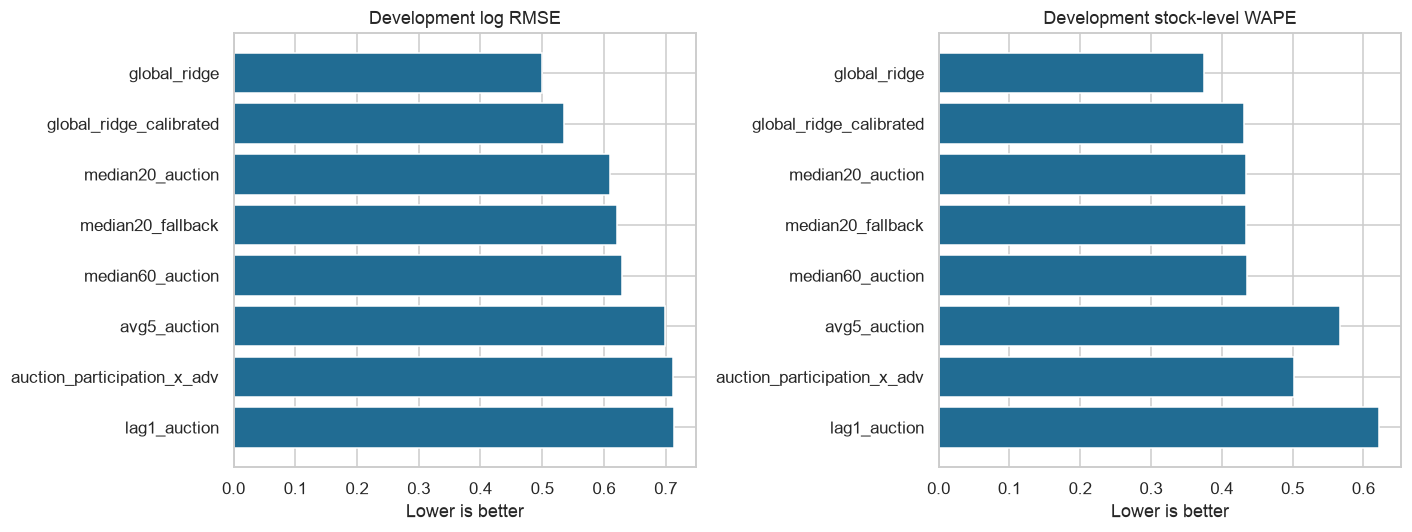

In [4]:
baseline_annual = read_study('07_temporal_baselines', 'overall_baseline_metrics.csv')
eligible_counts = (read_study('09_global_finalists', 'global_finalist_metrics.csv')
                   .groupby('test_year').observations.first())
# Derive coverage from the full eligible denominator, including rules with missing forecasts.
baseline_annual['coverage'] = baseline_annual.observations / baseline_annual.test_year.map(eligible_counts)
assert baseline_annual.coverage.between(0, 1).all()
baseline_dev = (baseline_annual[baseline_annual.test_year.isin(DEV_YEARS)]
                .groupby('model')[['coverage', 'rmse_log', 'wape', 'mae_raw', 'aggregate_bias']].mean()
                .sort_values('rmse_log'))
display(baseline_dev)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title in zip(axes, ['rmse_log', 'wape'], ['Development log RMSE', 'Development stock-level WAPE']):
    values = baseline_dev[metric]
    ax.barh(values.index, values, color='#216c93')
    ax.invert_yaxis()
    ax.set(title=title, xlabel='Lower is better')
plt.tight_layout(); plt.show()

The initial share-total calibration moved forecasts toward the observed share total, with higher error on other metrics. It illustrates why selecting on aggregate bias alone can produce a different result from selecting on proportional and absolute-share accuracy.

## Which ridge specifications were tried?

| Experiment | Variants examined | Purpose |
| --- | --- | --- |
| Historical window | Expanding from 2015, rolling five years, rolling three years | Trade historical sample size against changing relationships |
| Ridge penalty | Chronological validation over a penalty grid | Control shrinkage without choosing on the forecast year |
| Feature families | Auction core, additions to core, removals from the full model | Find the incremental value of calendar, liquidity and other sources |
| Target | Direct log level, median-relative residual, ADV-relative target, later log growth | Separate stock scale from the quantity being predicted |
| Observation weights | Uniform, stock balanced, recent-data weighting, large-auction weighting | Examine which errors the fit emphasises |
| Sample size and seed | 100,000, 350,000 and 700,000 rows | Assess sampling variability and the return from more ridge training rows |
| Global architecture | Pooled slopes, segment interactions, independent segment fits and specialists | Test whether different stocks need different fitted relationships |

### Windows, weights and feature families

The tables below use the completed robustness experiments. These changes were initially tested separately. The later finalist study combines selected choices and provides the relevant ranking for choosing the global benchmark.

In [5]:
window_annual = read_study('08_global_robustness', 'window_robustness_metrics.csv')
objective_annual = read_study('08_global_robustness', 'objective_and_target_metrics.csv')
group_annual = read_study('08_global_robustness', 'economic_feature_group_metrics.csv')
display(Markdown('**Saved experiment — development metrics by historical window**'))
display(development(window_annual, 'window')[['rmse_log', 'wape', 'aggregate_bias']])
display(Markdown('**Saved experiment — development metrics by target and weighting objective**'))
display(development(objective_annual, 'objective')[['rmse_log', 'wape', 'aggregate_bias']])
groups = (group_annual[group_annual.test_year.isin(DEV_YEARS)].groupby('specification')
          .agg(features=('feature_count', 'first'), log_RMSE=('rmse_log', 'mean'),
               WAPE=('wape', 'mean'), delta_log_RMSE=('rmse_delta_vs_full', 'mean'))
          .sort_values('log_RMSE'))
display(Markdown('**Saved experiment — economic feature families**'))
display(groups)

**Saved experiment — development metrics by historical window**

,rmse_log,wape,aggregate_bias
window,,,
rolling5,0.4961,0.3717,-0.1437
rolling3,0.4966,0.3713,-0.1423
expanding,0.4990,0.3767,-0.1368


**Saved experiment — development metrics by target and weighting objective**

,rmse_log,wape,aggregate_bias
objective,,,
median20_log_residual,0.4916,0.3710,-0.1291
log_level_recent_weighted,0.4949,0.3735,-0.1441
log_level_uniform,0.4990,0.3767,-0.1368
log_level_stock_balanced,0.5045,0.3836,-0.1252
log_level_large_auction_weighted,0.5170,0.3896,-0.0869
log_auction_to_adv20,0.6516,0.4077,-0.0383


**Saved experiment — economic feature families**

,features,log_RMSE,WAPE,delta_log_RMSE
specification,,,,
full_drop__Size and history,89,0.4986,0.3754,-0.0004
full_drop__Returns and price,88,0.4989,0.3768,-0.0000
full_drop__Security and corporate actions,95,0.4989,0.3767,-0.0000
full_drop__Sector state,91,0.4990,0.3768,-0.0000
full_model,99,0.4990,0.3767,0.0000
full_drop__Market state,91,0.4991,0.3775,0.0002
full_drop__Liquidity,83,0.4994,0.3751,0.0004
auction_core_plus__Calendar,42,0.5006,0.3765,0.0016
auction_core_plus__Liquidity,35,0.5769,0.4305,0.0779


Auction history and calendar information supplied much of the linear signal. The feature-family experiment motivated a compact auction–calendar–liquidity model. The coefficient table later should be read jointly with these group tests, because correlated inputs can share a signal and change each other's fitted slopes.

The sample-size study and shuffled-target check below were run on 2025 during the earlier audit. They are supporting diagnostics. The shuffled target destroys the pairing between inputs and auction volume, after which accuracy collapses. Increasing the ridge sample from 350,000 to 700,000 rows gave little improvement in that specific experiment.

In [6]:
display(read_study('08_global_robustness', 'training_sample_sensitivity_summary.csv'))
display(read_study('08_global_robustness', 'shuffled_target_placebo.csv'))
growth = saved('experiments/22_full_feature_ridge_growth/development_metrics.csv')
display(Markdown('**Saved experiment — matched 58/99-feature and target comparison**'))
display(growth[['model', 'rmse_log', 'wape', 'rmse_raw', 'aggregate_bias']])

,training_rows,mean_rmse_log,std_rmse_log,mean_wape,std_wape
0,100000,0.4516,0.0007,0.3560,0.0017
1,350000,0.4509,0.0002,0.3565,0.0003
2,700000,0.4510,0.0003,0.3558,0.0004


,model,test_year,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
0,shuffled_target_placebo,2025,150000,"285,520.2894",0.8979,1.5156,1.8875,0.1033,-0.8569


**Saved experiment — matched 58/99-feature and target comparison**

,model,rmse_log,wape,rmse_raw,aggregate_bias
0,compact58_median20,0.4881,0.3674,"657,159.7618",-0.1450
1,compact58_log_growth,0.4910,0.3743,"659,832.0911",-0.1480
2,full99_median20,0.4878,0.3666,"656,926.5993",-0.1448
3,full99_log_growth,0.4905,0.3740,"659,286.3502",-0.1428
4,frozen_compact58_median20,0.4876,0.3680,"658,440.0852",-0.1438


The later target comparison also retained the median-relative residual. With matched 58-feature ridge fits, log growth recorded development log RMSE of approximately **0.4910**, against **0.4881** for the median-relative target. The 99-feature log-growth model also trailed its median-relative control. Notebook 02 gives the full target definitions and stability evidence.

## Select the global ridge benchmark

Seven finalists combined the candidate windows, targets, weights and feature families. The selection rule treats a model within **0.002 development log RMSE** of the best as practically tied, then prefers fewer source features. That threshold is a project research convention. It has yet to be linked to an execution-cost acceptance criterion.

,source_feature_count,development_rmse_log,development_wape,development_bias,confirmation_rmse_log,within_practical_tolerance,selected_global_champion
candidate,,,,,,,
"Global 99, recent weighting",99,0.4868,0.3673,-0.1398,0.4461,True,False
"Global 99, median residual",99,0.4871,0.3669,-0.1438,0.4501,True,False
"Global 58, median residual",58,0.4876,0.3680,-0.1438,0.4451,True,True
"Global 42, auction + calendar",42,0.4906,0.3690,-0.1398,0.4479,False,False
"Global 99, 3-year history",99,0.4922,0.3674,-0.1402,0.4489,False,False
"Global 99, direct log",99,0.4961,0.3717,-0.1437,0.4532,False,False
"Global 99, expanding direct log",99,0.4990,0.3767,-0.1368,0.4512,False,False


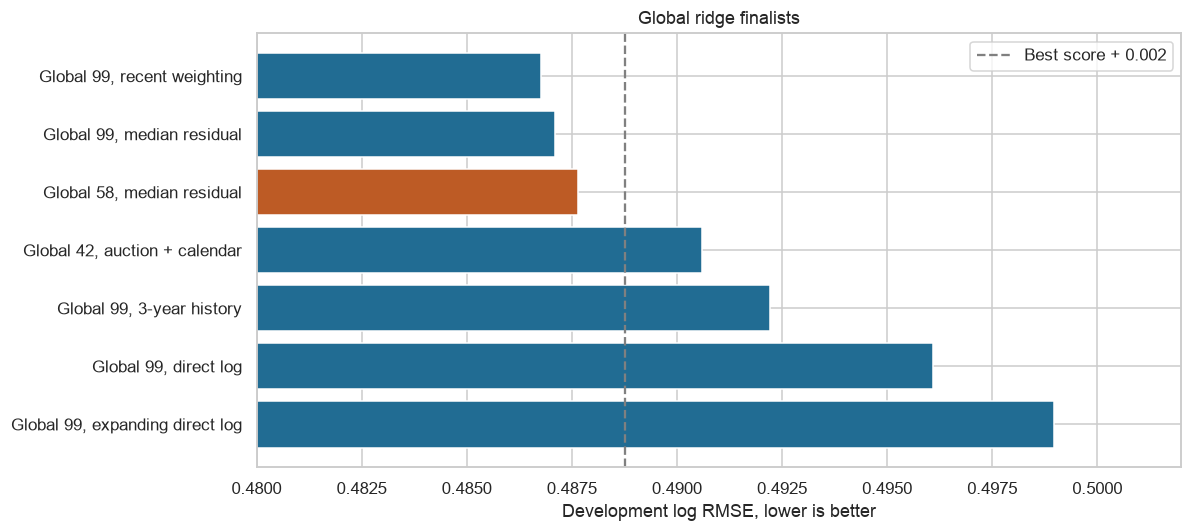

In [7]:
finalists = read_study('09_global_finalists', 'global_finalist_selection.csv')
specifications = read_study('09_global_finalists', 'finalist_specifications.csv')
finalist_table = finalists.merge(specifications[['candidate', 'window', 'target', 'weight']], on='candidate', validate='one_to_one')
columns = ['candidate', 'source_feature_count', 'development_rmse_log', 'development_wape',
           'development_bias', 'confirmation_rmse_log', 'within_practical_tolerance', 'selected_global_champion']
display(finalist_table[columns].assign(candidate=lambda d: d.candidate.map(short_names)).set_index('candidate'))
fig, ax = plt.subplots(figsize=(11, 5))
ordered = finalists.sort_values('development_rmse_log')
ax.barh([short_names[c] for c in ordered.candidate], ordered.development_rmse_log,
        color=['#bd5b25' if c == CHAMPION else '#216c93' for c in ordered.candidate])
ax.axvline(ordered.development_rmse_log.min() + .002, linestyle='--', color='grey', label='Best score + 0.002')
ax.set(xlim=(.480, .502), xlabel='Development log RMSE, lower is better', title='Global ridge finalists')
ax.invert_yaxis(); ax.legend()
plt.tight_layout(); plt.show()
assert finalists.loc[finalists.selected_global_champion, 'candidate'].tolist() == [CHAMPION]

The 99-feature model with recent-data weighting had the lowest development log RMSE, **0.48677**. The compact 58-feature model scored **0.48764**, a difference of **0.00088**. Under the recorded tie rule, the compact model became the frozen ridge benchmark. Its selected sources comprise 19 auction-history, 23 calendar and 16 liquidity features.

The 42-feature auction–calendar model lost enough accuracy to fall outside the tie range. Keeping liquidity therefore mattered to the final compact specification. This is a choice among ridge specifications. The LightGBM comparison follows at Checkpoint 3.

In [8]:
feature_catalog = saved('eda/05_feature_engineering/enriched_feature_catalog.csv')
selected_sources = feature_catalog[feature_catalog.variable.isin(FROZEN['features'])]
display(selected_sources.groupby('group').size().rename('selected_sources').to_frame())
coefficient_stability = read_study('09_global_finalists', 'champion_coefficient_stability.csv')
coefficient_stability['absolute_mean'] = coefficient_stability.mean_coefficient.abs()
display(coefficient_stability.sort_values('absolute_mean', ascending=False)
        [['source_feature', 'estimates', 'mean_coefficient', 'sign_consistency']].head(15))

,selected_sources
group,
Auction history,19
Calendar,23
Liquidity,16


,source_feature,estimates,mean_coefficient,sign_consistency
45,quarterly_options_expiry,4,1.6264,1.0000
41,median20_auction_volume,4,-1.3710,1.0000
26,is_last_trading_day_month,4,0.7131,1.0000
19,is_early_close,4,-0.5685,1.0000
42,median60_auction_volume,4,0.4381,1.0000
33,lag1_auction_volume,4,0.3827,1.0000
17,early_close_month_end_window,4,-0.3332,1.0000
34,lag1_daily_volume,4,0.2819,1.0000
35,lag1_dollar_volume,4,-0.2537,1.0000
9,avg20_dollar_volume,4,0.2477,1.0000


## Worked example with chronological tuning and fitting

This cell fits the selected 58-feature ridge recipe for 2022. It reuses the feature panel constructed in notebook 03 or a saved local copy. It uses the original row caps and searches all seven penalties on 2021 before refitting through 2021. The freshly ordered historical samples can differ from the original run, so its score is a worked refit and is excluded from the saved ranking tables.

In [9]:
paths = [PROJECT_ROOT / 'outputs/eda/05_feature_engineering/enriched_daily_panel.parquet',
         PROJECT_ROOT / 'midterm presentation/data_analysis/cache/enriched_daily_panel.parquet',
         PROJECT_ROOT / 'outputs/experiments/21_ridge_target_definitions/daily_panel.parquet']
PANEL = next((p for p in paths if p.is_file()), None)
if PANEL is None:
    import nbformat
    source = nbformat.read(PROJECT_ROOT / 'notebooks/05_feature_engineering_enriched_daily_panel.ipynb', as_version=4)
    construction = next(c.source for c in source.cells if c.cell_type == 'code' and c.source.startswith('panel_sql ='))
    exec(construction.split('escaped_path =')[0])
    PANEL = Path(work.name) / 'features.parquet'
    con.execute(f"COPY ({panel_sql}) TO '{PANEL}' (FORMAT PARQUET, COMPRESSION ZSTD)")

features = FROZEN['features']
context = ['date', 'permno', 'auction_volume', 'log1p_auction_volume', 'median20_auction_volume']
projection = ', '.join(f'"{name}"' for name in dict.fromkeys(context + features))
con.execute('SET threads=1')
def historical_rows(start, end, limit=None, seed=42):
    sample = f'USING SAMPLE {limit} ROWS (reservoir, {seed})' if limit else ''
    return sql(f"""
        SELECT * FROM (
            SELECT {projection} FROM read_parquet('{PANEL}')
            WHERE eligible_target AND date >= DATE '{start}' AND date < DATE '{end}'
            ORDER BY date, permno
        ) {sample} ORDER BY date, permno
    """)

template = json.loads((RESULTS / 'reproduction/03_compact_nonlinear/models/preprocessor_2022.json').read_text())
boolean = [f for f in features if f in template['boolean']]
categorical = [f for f in features if f in template['categorical']]
continuous = [f for f in features if f not in boolean + categorical]
types = (continuous, boolean, categorical)

def target_and_reference(train, score):
    fallback = float(train.auction_volume.median())
    target = train.log1p_auction_volume.to_numpy(float) - np.log1p(train.median20_auction_volume.fillna(fallback).to_numpy(float))
    reference = np.log1p(score.median20_auction_volume.fillna(fallback).to_numpy(float))
    return target, reference

tune = historical_rows('2016-01-01', '2021-01-01', 250000, 42)
validation = historical_rows('2021-01-01', '2022-01-01', 120000, 43)
x_tune, preprocessing = fit_preprocessor(tune, *types)
x_validation = apply_preprocessor(validation, preprocessing, *types)
z_tune, validation_reference = target_and_reference(tune, validation)
bounds = np.quantile(tune.log1p_auction_volume, [.001, .999])
trials = []
for strength in [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    coefficients = fit_ridge(x_tune, z_tune, strength)
    log_forecast = np.clip(validation_reference + predict_ridge(x_validation, coefficients), *bounds)
    error = log_forecast - validation.log1p_auction_volume.to_numpy(float)
    trials.append({'penalty': strength, 'validation_log_RMSE': np.sqrt(np.mean(error ** 2))})
trials = pd.DataFrame(trials)
best = trials.loc[trials.validation_log_RMSE.idxmin()]
display(trials.assign(penalty=trials.penalty.map(lambda value: f'{value:.0e}')))
assert tune.date.max() < validation.date.min()
del tune, validation, x_tune, x_validation
refit = historical_rows('2017-01-01', '2022-01-01', 350000, 44)
test = historical_rows('2022-01-01', '2023-01-01')
x_refit, preprocessing = fit_preprocessor(refit, *types)
x_test = apply_preprocessor(test, preprocessing, *types)
z_refit, test_reference = target_and_reference(refit, test)
coefficients = fit_ridge(x_refit, z_refit, float(best.penalty))
bounds = np.quantile(refit.log1p_auction_volume, [.001, .999])
forecast = np.maximum(np.expm1(np.clip(test_reference + predict_ridge(x_test, coefficients), *bounds)), 0)
assert refit.date.max() < test.date.min()
assert np.isfinite(x_refit).all() and np.isfinite(x_test).all()
display(pd.Series(score_shares(test.auction_volume, forecast), name='2022 worked refit').to_frame())
print(f'Selected historical penalty {best.penalty:g}. Forecasted {len(test):,} complete eligible stock-days.')
del refit, test, x_refit, x_test
_ = con.execute('SET threads=4')

,penalty,validation_log_RMSE
0,1e-07,0.5990
1,1e-06,0.5990
2,1e-05,0.5990
3,1e-04,0.5991
4,1e-03,0.6004
5,1e-02,0.6153
6,1e-01,0.6534


,2022 worked refit
observations,"328,634.0000"
mae_raw,"73,859.9341"
wape,0.3795
mae_log,0.3636
rmse_log,0.5346
spearman,0.9489
aggregate_bias,-0.1549
rmse_raw,"555,754.7766"
r2_raw,0.3678


Selected historical penalty 1e-07. Forecasted 328,634 complete eligible stock-days.


## Verify the saved global comparison from row-level predictions

The next cell recomputes all seven finalists' annual metrics from their saved out-of-time forecasts. It verifies unique keys, finite nonnegative predictions, common rows and agreement with the saved annual tables. This checks the numerical evidence used in the ranking independently of the worked refit above.

In [10]:
finalist_annual = read_study('09_global_finalists', 'global_finalist_metrics.csv')
verification = []
for year in [2022, 2023, 2024, 2025]:
    path = BASE / f'09_global_finalists/predictions/global_finalist_predictions_{year}.parquet'
    predictions = sql(f"SELECT * FROM read_parquet('{path}')")
    assert not predictions.duplicated(['date', 'permno']).any()
    assert predictions.date.dt.year.eq(year).all()
    for name in specifications.candidate:
        actual = score_shares(predictions.auction_volume, predictions[name])
        reference = finalist_annual.query('test_year == @year and candidate == @name').iloc[0]
        keys = ['observations', 'mae_raw', 'wape', 'mae_log', 'rmse_log', 'spearman', 'aggregate_bias']
        np.testing.assert_allclose([actual[k] for k in keys], reference[keys].to_numpy(float), rtol=1e-9, atol=1e-9)
        verification.append({'year': year, 'candidate': name, 'rows': actual['observations'], 'verified': True})
verification = pd.DataFrame(verification)
display(verification.groupby('year').agg(candidates=('candidate', 'size'),
                                         common_stock_days=('rows', 'first'), all_verified=('verified', 'all')))
assert verification.groupby('year').rows.nunique().eq(1).all()

,candidates,common_stock_days,all_verified
year,,,
2022,7,328634,True
2023,7,318679,True
2024,7,316212,True
2025,7,307853,True


## Should different stocks have separate models?

Global errors differ across size, liquidity, auction intensity and history groups. That motivates testing whether the relationship between features and auction volume differs enough to warrant separate coefficients.

The saved study tested nine architectures against the frozen 58-feature ridge and a second global reference, the 99-feature recently weighted model. All segment assignments use available daily features. Size, liquidity and intensity use low/mid/high thirds of historical cross-sectional percentiles. The size–liquidity grid uses two halves in each dimension. A stock can move between groups as its lagged characteristics change.

| Architecture | What changes |
| --- | --- |
| Pooled interactions | One global ridge, with group-specific intercept shifts and interactions for 14 selected auction/liquidity sources |
| Hard splits | Independent ridge coefficients within size, liquidity, intensity, or size × liquidity groups |
| Event hybrid | Specialist residual regressions on quarterly expiry, monthly expiry and month-end, with a global fit elsewhere |
| History hybrid | Direct log-level specialist for fewer than 20 prior auctions, with the residual model elsewhere |

Event groups are disjoint, with quarterly expiry, monthly expiry, month-end, early close and regular in that order. A specialist needs at least 2,000 training rows and otherwise uses the global fallback. The history experiment loads additional rare-history training rows rather than relying entirely on a global reservoir sample. Preprocessing is fitted on the shared historical sample before coefficients are fitted within groups.

,candidate,architecture,segmentation,estimation
0,interaction_size,pooled interaction,size tertiles,Residual target; selected slopes vary
1,interaction_liquidity,pooled interaction,liquidity tertiles,Residual target; selected slopes vary
2,interaction_intensity,pooled interaction,auction-intensity tertiles,Residual target; selected slopes vary
3,split_size,hard split,size tertiles,Independent residual models
4,split_liquidity,hard split,liquidity tertiles,Independent residual models
5,split_intensity,hard split,auction-intensity tertiles,Independent residual models
6,split_size_liquidity_2x2,hard split,2x2 size×liquidity,Independent residual models
7,event_hybrid,specialist hybrid,calendar event regime,Specialists for non-regular regimes; global fa...
8,history_hybrid,specialist hybrid,fewer than 20 prior auctions,Pooled log-level specialist; residual model ot...


,architecture,development_rmse_log,development_wape,development_bias,confirmation_rmse_log,confirmation_wape,eligible_general_replacement
candidate,,,,,,,
Separate size models,hard split,0.4865,0.3641,-0.1518,0.4463,0.3421,False
Separate size × liquidity models,hard split,0.4867,0.3643,-0.1520,0.4469,0.3431,False
"Global 99, recent weighting",global reference,0.4868,0.3673,-0.1398,0.4461,0.3414,False
Separate intensity models,hard split,0.4872,0.3682,-0.1397,0.4472,0.3462,False
Global + size interactions,pooled interaction,0.4874,0.3659,-0.1506,0.4469,0.3437,False
Global + intensity interactions,pooled interaction,0.4875,0.3681,-0.1414,0.4472,0.3458,False
"Global 58, median residual",global reference,0.4876,0.3680,-0.1438,0.4451,0.3456,False
Separate liquidity models,hard split,0.4877,0.3657,-0.1516,0.4470,0.3432,False
Global + liquidity interactions,pooled interaction,0.4879,0.3661,-0.1530,0.4470,0.3438,False


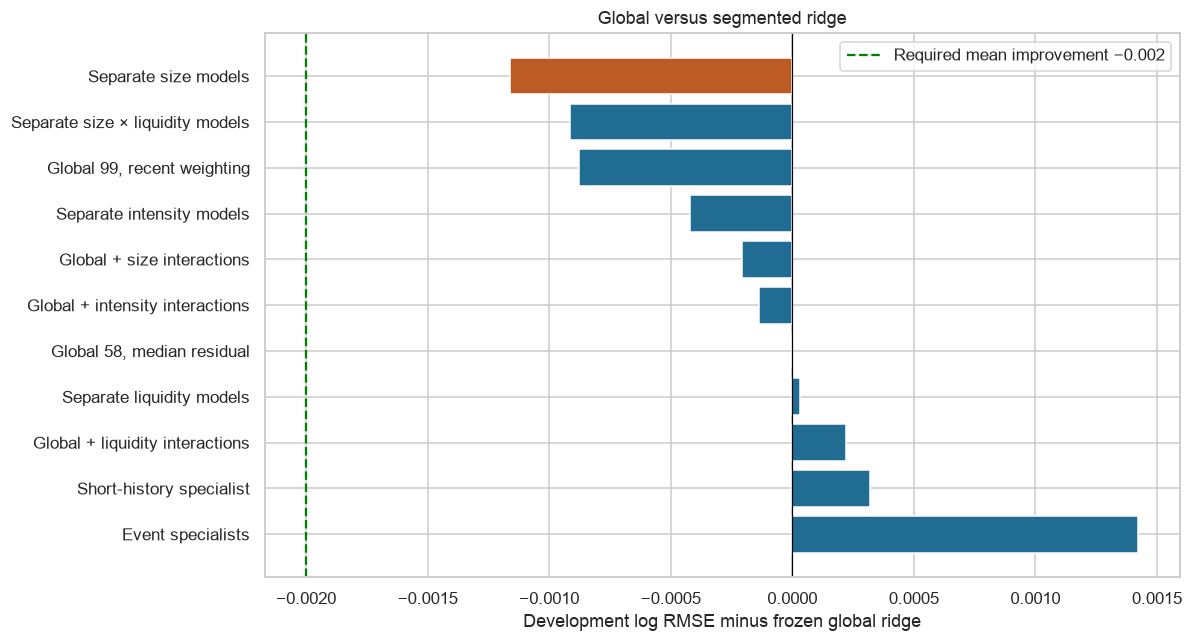

In [11]:
design = read_study('10_segmentation_tests', 'candidate_design.csv')
segment_annual = read_study('10_segmentation_tests', 'segmentation_candidate_metrics.csv')
decision = read_study('10_segmentation_tests', 'segmentation_decision_table.csv')
display(design)
columns = ['candidate', 'architecture', 'development_rmse_log', 'development_wape',
           'development_bias', 'confirmation_rmse_log', 'confirmation_wape', 'eligible_general_replacement']
display(decision[columns].assign(candidate=lambda d: d.candidate.map(short_names)).set_index('candidate'))
fig, ax = plt.subplots(figsize=(11, 6))
ordered = decision.sort_values('rmse_change_vs_frozen')
ax.barh([short_names[c] for c in ordered.candidate], ordered.rmse_change_vs_frozen,
        color=['#bd5b25' if c == 'split_size' else '#216c93' for c in ordered.candidate])
ax.axvline(-.002, color='green', linestyle='--', label='Required mean improvement −0.002')
ax.axvline(0, color='black', linewidth=.8)
ax.set(xlabel='Development log RMSE minus frozen global ridge', title='Global versus segmented ridge')
ax.invert_yaxis(); ax.legend()
plt.tight_layout(); plt.show()

## Why the best split did not replace the global model

The **size split** had the strongest segmented development point estimate, **0.48648** log RMSE versus **0.48764** for the frozen global ridge. Its gain was **0.00116**, below the required 0.002. It improved WAPE from **36.80% to 36.41%**, while aggregate bias became more negative, from **−14.38% to −15.18%**. In 2025 its log RMSE was **0.44634**, compared with **0.44512** for the frozen global model.

The historical adoption decision required the practical mean improvement, a lower RMSE than the secondary global reference, a favorable paired log-MAE interval, and no development year more than 0.002 worse. No tested segmented architecture met every condition. The table below reconstructs those decisions from the saved annual metrics and intervals.

,practical_rmse_improvement,beats_secondary_rmse,paired_log_mae_significant,stable_each_development_year,eligible_general_replacement
candidate,,,,,
split_size,False,True,False,True,False
split_size_liquidity_2x2,False,True,False,True,False
rolling5_residual_recent_full,False,False,False,True,False
split_intensity,False,False,False,True,False
interaction_size,False,False,False,True,False
interaction_intensity,False,False,False,True,False
rolling5_residual_auction_calendar_liquidity,False,False,False,True,False
split_liquidity,False,False,False,True,False
interaction_liquidity,False,False,False,True,False


,candidate,mean_difference,ci_2_5,ci_97_5,dates
12,split_size,-0.0003,-0.0007,0.0001,753


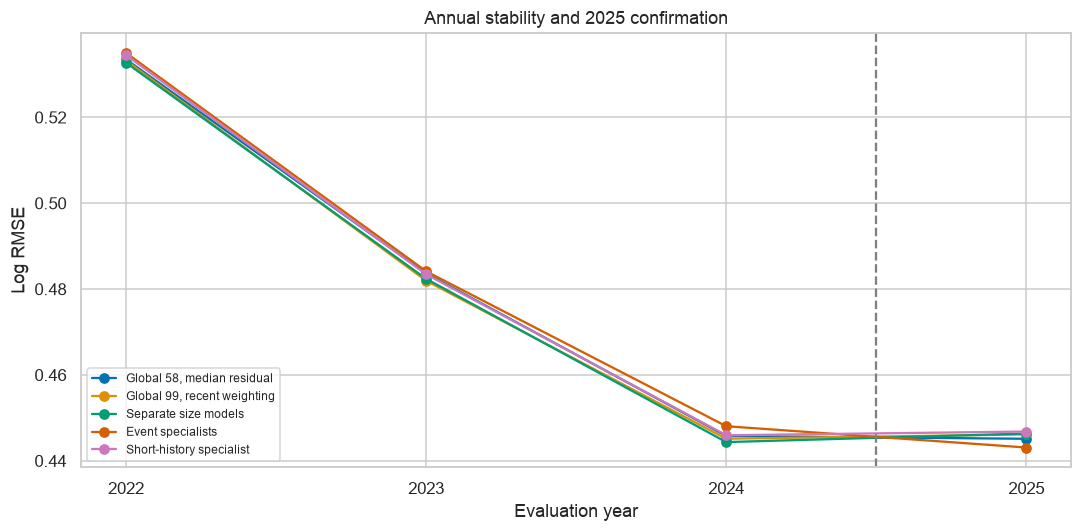

In [12]:
annual_scores = segment_annual.pivot(index='candidate', columns='test_year', values='rmse_log')
dev_scores = annual_scores[DEV_YEARS]
mean_improvement = dev_scores.mean(axis=1) - dev_scores.loc[CHAMPION].mean()
stability = dev_scores.sub(dev_scores.loc[CHAMPION], axis=1).max(axis=1) <= .002
bootstrap = read_study('10_segmentation_tests', 'segmentation_date_block_bootstrap.csv')
paired = bootstrap.query("reference == @CHAMPION and period == 'development_2022_2024' and metric == 'log_mae_difference'")
checks = decision.set_index('candidate')[['practical_rmse_improvement', 'beats_secondary_rmse',
          'paired_log_mae_significant', 'stable_each_development_year', 'eligible_general_replacement']].copy()
np.testing.assert_allclose(decision.set_index('candidate').rmse_change_vs_frozen.sort_index(), mean_improvement.sort_index(), atol=1e-12)
assert checks.stable_each_development_year.equals(stability.reindex(checks.index))
assert (checks.eligible_general_replacement == checks.iloc[:, :4].all(axis=1)).all()
display(checks)
size_interval = paired.query("candidate == 'split_size'")
display(size_interval[['candidate', 'mean_difference', 'ci_2_5', 'ci_97_5', 'dates']])
fig, ax = plt.subplots(figsize=(10, 5))
for name in [CHAMPION, SECONDARY, 'split_size', 'event_hybrid', 'history_hybrid']:
    ax.plot(annual_scores.columns, annual_scores.loc[name], marker='o', label=short_names[name])
ax.axvline(2024.5, color='grey', linestyle='--')
ax.set(xticks=[2022, 2023, 2024, 2025], xlabel='Evaluation year', ylabel='Log RMSE', title='Annual stability and 2025 confirmation')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The size split's development paired log-MAE interval was approximately **−0.00071 to +0.00013**. It included zero. These saved intervals resample **whole dates independently**, carrying each date's cross-section together. Although the original filenames contain “date_block”, this implementation uses one-date resampling and does not preserve dependence between adjacent dates. It measures daily log MAE and daily WAPE differences, which differ from the headline equal-year log-RMSE and annual-WAPE estimands. It is supporting historical evidence and conditions on fitted forecasts.

### What the segment results reveal

The following table averages the three development years within each group and includes changes versus the frozen global model. A negative change means lower error. Rare categories also retain their stock-day counts.

dimension  observations  rmse_log   wape  \
candidate       segment                                                      
event_hybrid    early_close           event          6289    0.4359 0.3069   
                month_end             event         46239    0.6935 0.4978   
                monthly_expiry        event         30713    0.5475 0.3780   
                quarterly_expiry      event         15431    0.8100 0.5389   
                regular               event        864853    0.4655 0.3256   
history_hybrid  cold_0_4            history           758    1.4264 0.8687   
                developing_5_19     history          2466    0.8394 0.5154   
                seasoned_20_plus    history        960301    0.4852 0.3665   
split_intensity high              intensity        298313    0.4635 0.3560   
                low               intensity        330099    0.5677 0.4123   
                mid               intensity        335113    0.4171 0.3412   
split_liquidity high              liquidity        335621    0.4600 0.3635   
                low               liquidity        293593    0.5442 0.3884   
                mid               liquidity        334311    0.4620 0.3718   
split_size      high                   size        335502    0.4083 0.3385   
                low                    size        294892    0.6001 0.4709   
                mid                    size        333131    0.4461 0.4001   

                                  rmse_change_vs_frozen  wape_change_vs_frozen  
candidate       segment                                                         
event_hybrid    early_close                      0.0024                 0.0090  
                month_end                        0.0073                -0.0029  
                monthly_expiry                   0.0052                -0.0023  
                quarterly_expiry                 0.0044                -0.0071  
                regular                          0.0007                -0.0006  
history_hybrid  cold_0_4                        -0.0065                -0.0533  
                developing_5_19                 -0.0125                -0.0053  
                seasoned_20_plus                 0.0004                -0.0010  
split_intensity high                            -0.0005                -0.0005  
                low                             -0.0005                 0.0039  
                mid                             -0.0003                -0.0023  
split_liquidity high                             0.0000                -0.0028  
                low                             -0.0004                 0.0010  
                mid                              0.0004                -0.0007  
split_size      high                            -0.0012                -0.0055  
                low                             -0.0025                -0.0004  
                mid                              0.0004                -0.0005

min     max
candidate                segment                            
event_hybrid             month_end             16609   16823
                         monthly_expiry        11161   11360
                         quarterly_expiry       5551    5727
history_hybrid           prior_lt_20            9108    9565
split_intensity          high                 108611  112370
                         low                  118265  119619
                         mid                  119365  121770
split_liquidity          high                 119850  121563
                         low                  107035  110793
                         mid                  119357  121402
split_size               high                 119834  121914
                         low                  107213  111372
                         mid                  118794  120873
split_size_liquidity_2x2 high_size__high_liq  128126  129715
                         high_size__low_liq    49705   54728
                         low_size__high_liq    49897   54227
                         low_size__low_liq    112919  120859

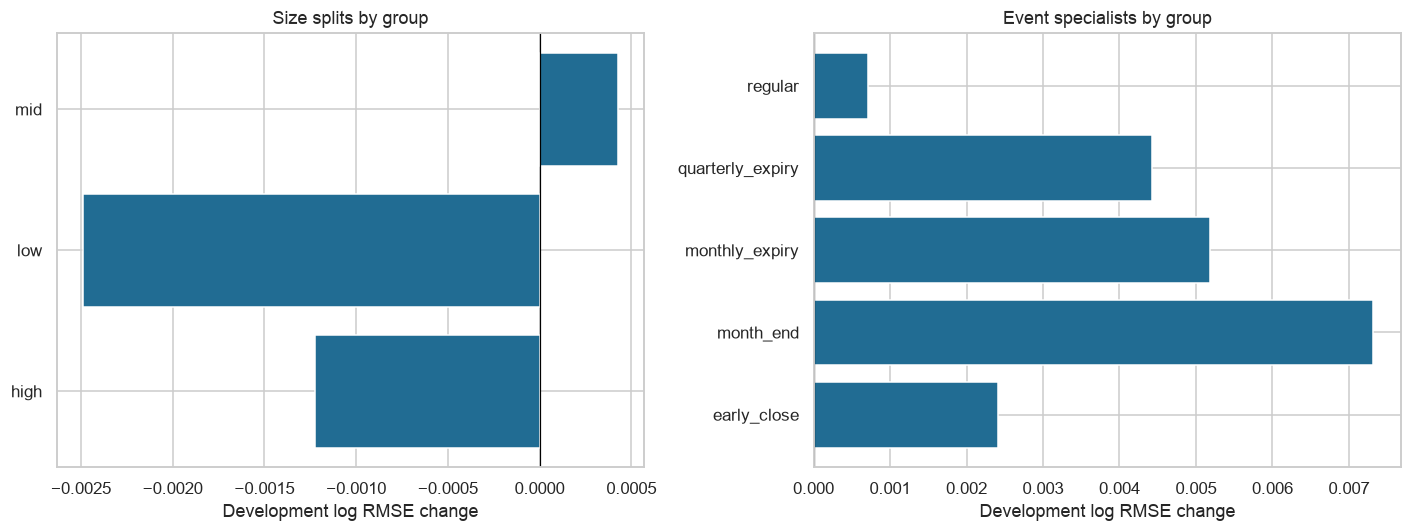

In [13]:
segments = read_study('10_segmentation_tests', 'segmentation_segment_metrics.csv')
focus = read_study('10_segmentation_tests', 'targeted_segment_improvements.csv')
display(focus[['candidate', 'dimension', 'segment', 'observations', 'rmse_log', 'wape',
               'rmse_change_vs_frozen', 'wape_change_vs_frozen']].set_index(['candidate', 'segment']))
counts = read_study('10_segmentation_tests', 'segment_training_counts.csv')
display(counts.groupby(['candidate', 'segment']).training_rows.agg(['min', 'max']))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, candidate, title in zip(axes, ['split_size', 'event_hybrid'], ['Size splits by group', 'Event specialists by group']):
    part = focus[focus.candidate.eq(candidate)]
    ax.barh(part.segment, part.rmse_change_vs_frozen, color='#216c93')
    ax.axvline(0, color='black', linewidth=.8)
    ax.set(title=title, xlabel='Development log RMSE change')
plt.tight_layout(); plt.show()

The size split improved low-size and high-size groups but slightly worsened the middle group. The low-size group's log-RMSE gain was around **0.00249**, yet its targeted log-MAE interval included zero. Splitting by liquidity produced a near tie overall and mixed group-level changes.

The event specialists reduced WAPE on some major event groups while worsening their development log RMSE. The history specialist improved the fewer-than-20-observation groups, but their small share of the universe and changes elsewhere left overall log RMSE slightly worse. Separate penalty selection for each complete architecture can change the global component as well, so ordinary-row forecasts can differ even in a specialist hybrid.

These outcomes establish the accuracy tradeoffs for the tested linear models. Several mechanisms could explain the limited gains. Segments share useful volume and calendar relationships already represented by the global inputs. Separate fits estimate more coefficients from smaller historical samples. Sparse event dates provide fewer independent observations than their stock-day count suggests. These are interpretations supported by the design and diagnostics, rather than an identified decomposition of why the splits failed.

In [14]:
targeted_intervals = read_study('10_segmentation_tests', 'targeted_segment_date_bootstrap.csv')
display(targeted_intervals[['candidate', 'segment', 'period', 'mean_log_mae_difference',
                            'ci_2_5', 'ci_97_5', 'dates', 'observations']].set_index(['candidate', 'segment']))
assert not decision.eligible_general_replacement.any()
assert not targeted_intervals.query("period == 'development_2022_2024'").ci_97_5.lt(0).any()

period  \
candidate      segment                                   
history_hybrid cold_0_4          development_2022_2024   
               cold_0_4              confirmation_2025   
               developing_5_19   development_2022_2024   
               developing_5_19       confirmation_2025   
event_hybrid   quarterly_expiry  development_2022_2024   
               quarterly_expiry      confirmation_2025   
               monthly_expiry    development_2022_2024   
               monthly_expiry        confirmation_2025   
               month_end         development_2022_2024   
               month_end             confirmation_2025   
split_size     low               development_2022_2024   
               low                   confirmation_2025   

                                 mean_log_mae_difference  ci_2_5  ci_97_5  \
candidate      segment                                                      
history_hybrid cold_0_4                          -0.0111 -0.0387   0.0162   
               cold_0_4                          -0.0703 -0.1124  -0.0301   
               developing_5_19                   -0.0024 -0.0213   0.0155   
               developing_5_19                   -0.0045 -0.0344   0.0259   
event_hybrid   quarterly_expiry                   0.0045 -0.0324   0.0509   
               quarterly_expiry                  -0.0549 -0.1165  -0.0172   
               monthly_expiry                     0.0051 -0.0029   0.0138   
               monthly_expiry                     0.0012 -0.0109   0.0125   
               month_end                          0.0041 -0.0162   0.0251   
               month_end                         -0.0463 -0.0880  -0.0049   
split_size     low                               -0.0001 -0.0012   0.0010   
               low                                0.0007 -0.0011   0.0024   

                                 dates  observations  
candidate      segment                                
history_hybrid cold_0_4            453           758  
               cold_0_4            151           247  
               developing_5_19     701          2466  
               developing_5_19     217           735  
event_hybrid   quarterly_expiry     12         15431  
               quarterly_expiry      4          4947  
               monthly_expiry       24         30713  
               monthly_expiry        8          9853  
               month_end            36         46239  
               month_end            12         14771  
split_size     low                 753        294892  
               low                 250        100643

## Where segmentation may still be useful

| Situation | Evidence and implication |
| --- | --- |
| Short-history stocks | Development point estimates improved within the intended group. A dedicated specialist could matter if serving those stocks is an explicit objective. Its development uncertainty remained wide |
| Major calendar events | Some WAPE gains and stronger 2025 subgroup results justify retaining the idea as a challenger. Development log accuracy weakened and there were only 12 quarterly-expiry dates across three years |
| Different operational objectives | A group-specific tolerance for share error, bias or coverage could motivate a different decision. That objective would need to be declared before selecting a new model |
| General size or liquidity splits | Current gains are small and mixed, with additional coefficients and less history per fit. The recorded overall selection rule retains the global model |
| Group diagnostics | Segmenting evaluation remains informative even when forecasting uses one global model. It identifies persistent weak areas and checks where an overall improvement comes from |

The 2025 specialist intervals are retrospective, exploratory evidence. Sparse events, many comparisons and reuse of inspected years limit the strength of conclusions drawn from individual subgroup intervals.

## Checkpoint 2 decision

Carry forward the **global 58-feature ridge**, using the median-relative log target, five-year rolling fit and uniform stock-day weights, as the linear benchmark. Keep the recently weighted 99-feature global model as a secondary reference. Retain the size and specialist experiments in the research record with their tradeoffs.

The global decision follows the recorded practical tie rule. The strongest segmented point estimate was slightly lower, and no segmented candidate met all replacement criteria. The worked chronological fit and the saved row-level metric checks above make the fitting and numerical evidence inspectable.

The next approved stage is notebook 05, covering LightGBM and the tuning that produced the daily champion.

## Source map

| Evidence | Repository source |
| --- | --- |
| Baseline rules and initial ridge | `outputs/eda/07_temporal_baselines` and `notebooks/07_temporal_baselines_and_global_benchmark.ipynb` |
| Windows, objectives, weights and feature families | `outputs/eda/08_global_robustness` and `notebooks/08_global_model_robustness_and_specification.ipynb` |
| Global finalist selection and row-level forecasts | `outputs/eda/09_global_finalists` and `notebooks/09_global_finalists_and_benchmark_freeze.ipynb` |
| Segmented architectures, samples, intervals and adoption rule | `outputs/eda/10_segmentation_tests` and `notebooks/10_segmentation_and_specialist_model_tests.ipynb` |
| Matched compact/full ridge and log growth | `outputs/experiments/22_full_feature_ridge_growth` |
| Fitting, imputation and metric implementation | `notebooks/modeling_utils.py` |

All source paths are relative to the repository root. This notebook reads existing results and uses temporary storage for its worked refit. It writes no model or source-data artifacts.

In [15]:
assert len(features) == 58
assert len(verification) == 28 and verification.verified.all()
assert int(verification.groupby('year').rows.first().sum()) == 1271378
print('Checkpoint 2 verified: 28 saved model-year metric comparisons, chronological worked fit and reconstructed architecture decisions.')
con.close()
work.cleanup()

Checkpoint 2 verified: 28 saved model-year metric comparisons, chronological worked fit and reconstructed architecture decisions.
